# Case 3: The budget: which 1,000 clients should Marketing call?

*Applies chapters 2, 4 and 5: precision derived, the metric chosen from business cost, and the threshold as a business decision, now under a budget. Also searched as: precision at k, lift chart, cumulative gains, top-k ranking.*

**Who needs the answer.** Kalpa Retail's Marketing team, who can afford 1,000 nudges for a slice this size, and Anand in Finance, who wants to know what the model buys that a random list would not. The business owner's question is the same bill as in case 2, with one new fact: the number of calls is capped.

**The questions on the way.** How many buyers does a random list of 1,000 find? How many does the top 1,000 by score find? What does that difference cost in rupees? How do you compare two lists fairly?

Case 2 ended with the cost threshold at 0.032 calling 7,438 clients, which Marketing cannot afford. This case adds the budget and reads the model as a ranking.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

# Load the day's public dataset once; later runs read the cached copy.
# UCI Bank Marketing, bank-additional-full.csv, CC BY 4.0 (Moro, Rita and Cortez, 2014).
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call (Monday's columns): who the client is, how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, Friday's envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

bank = load_bank()
train, val, test = week_split(bank)
model = logistic(COLS, bank).fit(train[COLS], (train["y"] == "yes").astype(int))
y_val = (val["y"] == "yes").astype(int).to_numpy()      # 1 = the client subscribed (a buyer)
p_val = model.predict_proba(val[COLS])[:, 1]             # the model's P(buy) for each validation client
print(f"rows {len(bank):,}; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed until Friday)")
print(f"buyers in validation: {y_val.sum():,} of {len(y_val):,}, a base rate of {y_val.mean():.2%}")

def cells(y, p, threshold):
    """The four boxes at one threshold: act (call, nudge) when the score is at or above it."""
    act = p >= threshold
    tp = int((act & (y == 1)).sum()); fp = int((act & (y == 0)).sum())
    fn = int((~act & (y == 1)).sum()); tn = int((~act & (y == 0)).sum())
    return tp, fp, fn, tn

rows 41,188; train 24,712, validation 8,238, test 8,238 (sealed until Friday)
buyers in validation: 928 of 8,238, a base rate of 11.26%


In [2]:
COST_FP, COST_FN, BUDGET = 40, 1200, 1000
called_at_cost = int((p_val >= 1 / 31).sum())
print(f"case 2's cost threshold calls {called_at_cost:,} clients; the budget allows {BUDGET:,}")
print("PASS  the cost threshold overshoots the budget" if called_at_cost > BUDGET else "CHECK budget")
order = np.argsort(-p_val)                      # clients from the highest score down
print("PASS  the ranking covers every validation client" if len(order) == len(y_val) == 8238 else "CHECK ranking")

case 2's cost threshold calls 7,438 clients; the budget allows 1,000
PASS  the cost threshold overshoots the budget
PASS  the ranking covers every validation client


## The options: which 1,000 clients go on the list?

1. **A random 1,000**, the list a team makes with no model.
2. **The first 1,000 rows** of the file, the list a hurried export makes.
3. **The top 1,000 by score**, the model read as a ranking.

**Predict before you run.** The base rate is 11.3 percent. How many buyers does the top 1,000 by score hold? (a) about 113, (b) about 250, (c) about 400, (d) about 900.

In [3]:
rng = np.random.default_rng(42)
random_found = np.mean([y_val[rng.choice(len(y_val), BUDGET, replace=False)].sum() for _ in range(500)])
first_found = y_val[:BUDGET].sum()
top_found = y_val[order[:BUDGET]].sum()
def budget_bill(found):
    return (BUDGET - found) * COST_FP + (y_val.sum() - found) * COST_FN
lists = pd.DataFrame([["random 1,000 (mean of 500 draws)", random_found], ["first 1,000 rows", first_found],
                      ["top 1,000 by score", top_found]], columns=["list", "buyers found"])
lists["precision at 1,000"] = lists["buyers found"] / BUDGET
lists["bill Rs"] = [budget_bill(f) for f in lists["buyers found"]]
print(lists.to_string(index=False, formatters={"buyers found": "{:.0f}".format, "precision at 1,000": "{:.3f}".format,
                                               "bill Rs": "{:,.0f}".format}))

                            list buyers found precision at 1,000   bill Rs
random 1,000 (mean of 500 draws)          112              0.112 1,014,264
                first 1,000 rows          123              0.123 1,001,080
              top 1,000 by score          404              0.404   652,640


**What happened.** The answer is (c): 404 of the top 1,000 buy, a precision at 1,000 of 0.404 against the 0.113 base rate, about 3.6 times a random list. With the calls capped, every call spent on a likely buyer is a call not wasted on an unlikely one, and the top 1,000 leaves a bill about Rs 3.6 lakh smaller than a random list in this slice. This is where the model earns its keep: under a budget, the ranking carries the decision.

## How does precision fall as the list grows?

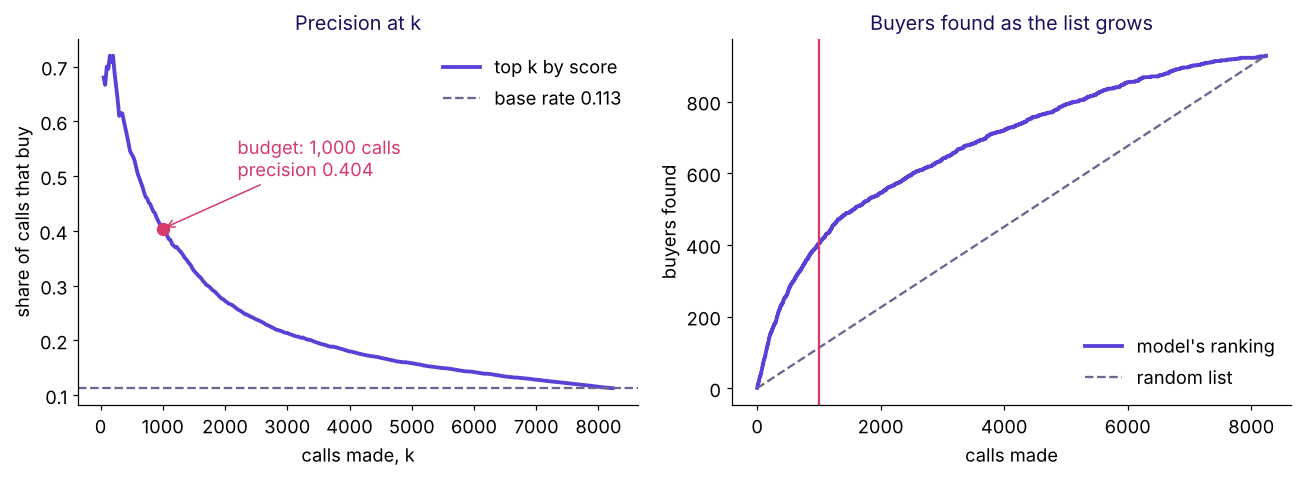

In [4]:
ks = np.arange(50, 8238, 25)
prec_k = np.array([y_val[order[:k]].mean() for k in ks])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(ks, prec_k, color=VIOLET, lw=2.5, label="top k by score")
axes[0].axhline(y_val.mean(), color=MUTED, ls="--", label=f"base rate {y_val.mean():.3f}")
axes[0].scatter([1000], [y_val[order[:1000]].mean()], color=ROSE, zorder=5, s=60)
axes[0].annotate("budget: 1,000 calls\nprecision 0.404", (1000, 0.404), (2200, 0.5), color=ROSE, arrowprops={"arrowstyle": "->", "color": ROSE})
axes[0].set_xlabel("calls made, k"); axes[0].set_ylabel("share of calls that buy"); axes[0].set_title("Precision at k", color=INK)
axes[0].legend(frameon=False)
found_k = np.cumsum(y_val[order])
axes[1].plot(np.arange(1, 8239), found_k, color=VIOLET, lw=2.5, label="model's ranking")
axes[1].plot([0, 8238], [0, y_val.sum()], color=MUTED, ls="--", label="random list")
axes[1].axvline(1000, color=ROSE, lw=1.5)
axes[1].set_xlabel("calls made"); axes[1].set_ylabel("buyers found"); axes[1].set_title("Buyers found as the list grows", color=INK)
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## The trap: is the longer list a better model?

A colleague reruns the ranking with a lower cut and reports: **"The new setting finds 544 buyers against our 404, a 35 percent improvement."** The 544 is real, and it comes from 2,000 calls. Two lists are only comparable at the same number of calls; Razorpay's fraud team writes the same rule for its alerts, that catching more by reviewing more "is a threshold change, not proof that the model improved" (Razorpay engineering blog, 10 September 2026, verified 28 October 2026). If Marketing believed the 35 percent, it would double the budget expecting a better model and pay more per buyer. The check is to compare at equal k and to price the cost per buyer found.

In [5]:
for k in (1000, 2000):
    found = y_val[order[:k]].sum()
    print(f"top {k:,}: {found} buyers, precision {found / k:.3f}, nudge spend per buyer found Rs {k * COST_FP / found:,.0f}")
print("PASS  the same model at 2,000 calls has lower precision than at 1,000" if y_val[order[:2000]].mean() < y_val[order[:1000]].mean() else "CHECK k")
print("PASS  the top 1,000 holds more than three times a random list's buyers" if top_found > 3 * random_found else "CHECK lift")

top 1,000: 404 buyers, precision 0.404, nudge spend per buyer found Rs 99
top 2,000: 544 buyers, precision 0.272, nudge spend per buyer found Rs 147
PASS  the same model at 2,000 calls has lower precision than at 1,000
PASS  the top 1,000 holds more than three times a random list's buyers


## A second route: which threshold does the budget set?

A budget is a threshold in disguise: calling the top 1,000 is the same as calling everyone whose score is at or above the 1,000th score. The cell finds that score and checks it calls the same clients. The cost rule says act above 0.032; the budget says act above about 0.18. When both hold, the stricter one binds, and here it is the budget.

In [6]:
t_budget = p_val[order[BUDGET - 1]]
tp, fp, fn, tn = cells(y_val, p_val, t_budget)
print(f"the 1,000th score is {t_budget:.3f}; at that threshold the model calls {tp + fp:,} and finds {tp}")
print("PASS  the budget threshold calls the same 1,000 and finds the same buyers" if tp + fp == BUDGET and tp == top_found else "CHECK budget threshold")
print(f"recall at the budget: {tp / (tp + fn):.3f}; precision {tp / (tp + fp):.3f}")

the 1,000th score is 0.182; at that threshold the model calls 1,000 and finds 404
PASS  the budget threshold calls the same 1,000 and finds the same buyers
recall at the budget: 0.435; precision 0.404


## What did this case establish, and what does it hand to Wednesday?

| Question | Answer from this run |
|---|---|
| Buyers in a random 1,000? | About 113, the base rate |
| Buyers in the top 1,000 by score? | 404, precision at 1,000 of 0.404, about 3.6 times random |
| What is the difference worth? | The bill falls from about Rs 10.1 lakh to Rs 6.5 lakh, about Rs 3.6 lakh, in this slice |
| How do you compare two lists? | At the same number of calls, with the spend per buyer found beside it |
| Which threshold binds? | The budget's 0.18, stricter than the cost rule's 0.032 |

**In the interview.** "Marketing can only afford 1,000 calls. Which metric do you report?" Precision at 1,000 against the base rate, with the bill beside it; the cost threshold would have asked for 7,438 calls.

Wednesday audits the columns these scores were built from: is every one of them known on the morning of the call?